In [1]:
import csv
import sys
from pathlib import Path

import torch
import matplotlib.pyplot as plt
import optuna

project_root = Path.cwd().resolve()
if not (project_root / "src/cnn_project").is_dir():
    project_root = project_root.parent
sys.path.insert(0, str(project_root / "src"))

from cnn_project.train import train_model
from cnn_project.model import EuroSATModel
from cnn_project.data import create_data_loaders

trial_dir = project_root / "Checkpoints/optuna_trials"
database_path = project_root / "experiments/optuna/eurosat_optuna.db"
study_storage = f"sqlite:///{database_path.as_posix()}"
study_name = "eurosat_cnn"

# False reloads saved results. True adds 20 new trials to this study.
RUN_SEARCH = False
N_TRIALS = 20
EPOCHS_PER_TRIAL = 30


In [2]:
if torch.cuda.is_available():
    device = torch.device("cuda")
    print("The model is using CUDA")
else:
    device = torch.device("cpu")
    print("The model is using CPU")

torch.manual_seed(42)


The model is using CPU
Out[2]: <torch._C.Generator at 0x7c58485f28f0>


In [3]:
def objective(trial):
    trial_dir.mkdir(parents=True, exist_ok=True)
    lr = trial.suggest_float("lr", 1e-4, 1e-2, log=True)
    gamma = trial.suggest_float("gamma", 0.5, 0.95)
    batch_size = trial.suggest_categorical("batch_size", [64, 128, 256, 512])

    train_loader, val_loader, _ = create_data_loaders(batch_size=batch_size)
    trial_model = EuroSATModel().to(device)
    history = train_model(
        model=trial_model,
        train_loader=train_loader,
        val_loader=val_loader,
        device=device,
        epochs=EPOCHS_PER_TRIAL,
        lr=lr,
        gamma=gamma,
    )

    csv_path = trial_dir / f"trial_{trial.number:03d}_history.csv"
    with csv_path.open("w", newline="") as file:
        writer = csv.writer(file)
        writer.writerow(history.keys())
        writer.writerows(zip(*history.values()))

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history["epoch"], history["train_loss"], label="Train")
    axes[0].plot(history["epoch"], history["val_loss"], label="Validation")
    axes[0].set(xlabel="Epoch", ylabel="Cross-entropy loss", title="Loss")
    axes[1].plot(history["epoch"], history["train_accuracy"], label="Train")
    axes[1].plot(history["epoch"], history["val_accuracy"], label="Validation")
    axes[1].set(xlabel="Epoch", ylabel="Accuracy", title="Accuracy", ylim=(0, 1))
    for ax in axes:
        ax.set_xlim(1, EPOCHS_PER_TRIAL)
        ax.grid(alpha=0.3)
        ax.legend()
    fig.suptitle(f"Trial {trial.number}: lr={lr:.2g}, gamma={gamma:.3f}, batch={batch_size}")
    fig.tight_layout()
    png_path = trial_dir / f"trial_{trial.number:03d}_curves.png"
    fig.savefig(png_path, dpi=150)
    plt.close(fig)
    print(f"Saved {png_path} and {csv_path}")

    return max(history["val_accuracy"])

if RUN_SEARCH:
    database_path.parent.mkdir(parents=True, exist_ok=True)
    study = optuna.create_study(
        direction="maximize",
        storage=study_storage,
        study_name=study_name,
        load_if_exists=True,
    )
    study.optimize(objective, n_trials=N_TRIALS)
elif database_path.is_file():
    study = optuna.load_study(study_name=study_name, storage=study_storage)
    print("Loaded the saved study; no new trials were run.")
else:
    study = None
    print("No saved study found. Set RUN_SEARCH = True to start tuning.")

completed_trials = [
    trial for trial in study.trials
    if trial.state == optuna.trial.TrialState.COMPLETE and trial.value is not None
] if study is not None else []

if completed_trials:
    print(f"Completed trials: {len(completed_trials)}")
    print(f"Best validation accuracy: {study.best_value:.2%}")
    print("Best parameters:", study.best_params)
elif study is not None:
    print("This study has no completed trials yet.")


Loaded the saved study; no new trials were run.
Completed trials: 20
Best validation accuracy: 95.78%
Best parameters: {'lr': 0.006331992329769813, 'gamma': 0.6962221733165475, 'batch_size': 64}


In [4]:
from IPython.display import Image, display

if completed_trials:
    best_trial = study.best_trial
    best_curve_path = trial_dir / f"trial_{best_trial.number:03d}_curves.png"
    print(f"Best trial: {best_trial.number}; validation accuracy: {best_trial.value:.2%}")
    if best_curve_path.is_file():
        display(Image(filename=str(best_curve_path)))
    else:
        print(
            "The best trial's curve image is not available locally. "
            "Its score and parameters are preserved in the study database."
        )
else:
    print("No completed trial to display yet.")


Best trial: 11; validation accuracy: 95.78%
The best trial's curve image is not available locally. Its score and parameters are preserved in the study database.


## Compare saved trials

When per-epoch CSV histories exist, plot their training and validation curves. Otherwise, show the completed trials' best validation scores from the Optuna database. Set `RUN_SEARCH = True` in the setup cell only when you want to add new trials.


Per-epoch CSV histories are not available locally. Showing saved best validation scores instead of training curves.


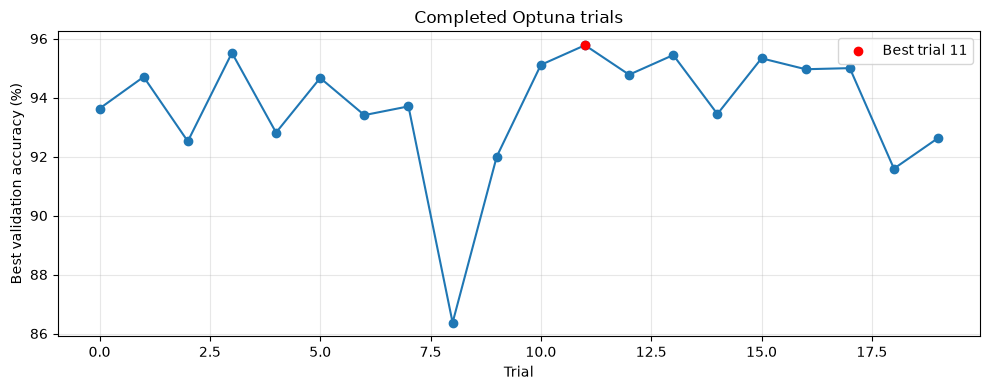

In [5]:
metrics = [
    ("train_loss", "Training loss"),
    ("val_loss", "Validation loss"),
    ("train_accuracy", "Training accuracy"),
    ("val_accuracy", "Validation accuracy"),
]
trials = {trial.number: trial for trial in completed_trials}
trial_histories = []
for path in sorted(trial_dir.glob("trial_*_history.csv")):
    trial_number = int(path.stem.split("_")[1])
    if trial_number not in trials:
        continue
    with path.open(newline="") as file:
        rows = list(csv.DictReader(file))
    if rows:
        trial_histories.append((trials[trial_number], rows))

if trial_histories:
    fig, axes = plt.subplots(2, 2, figsize=(15, 13), sharex=True)
    colors = plt.get_cmap("tab20")
    for index, (trial, rows) in enumerate(trial_histories):
        epochs = [int(row["epoch"]) for row in rows]
        params = trial.params
        label = (
            f"Trial {trial.number:02d} | batch {params['batch_size']} | "
            f"lr {params['lr']:.3g} | gamma {params['gamma']:.3f} | "
            f"best val {trial.value:.2%}"
        )
        for ax, (key, title) in zip(axes.flat, metrics):
            values = [float(row[key]) for row in rows]
            ax.plot(epochs, values, color=colors(index % 20), alpha=0.8,
                    linewidth=1.4, label=label)
            ax.set_title(title)
            ax.set_xlabel("Epoch")
            ax.grid(alpha=0.25)
    for ax in axes[1]:
        ax.set_ylim(0, 1)
    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=2, fontsize=8,
               bbox_to_anchor=(0.5, 0.01))
    fig.suptitle(f"Optuna training curves: {len(trial_histories)} trials")
    fig.tight_layout(rect=(0, 0.32, 1, 0.96))
    summary_path = trial_dir / "all_trials_curves.png"
    fig.savefig(summary_path, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved {summary_path}")
    if len(trial_histories) < len(completed_trials):
        print("Some completed trials have no local CSV history and are omitted from these curves.")
elif completed_trials:
    print(
        "Per-epoch CSV histories are not available locally. "
        "Showing saved best validation scores instead of training curves."
    )
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot([trial.number for trial in completed_trials],
            [100 * trial.value for trial in completed_trials], "o-")
    best_trial = study.best_trial
    ax.scatter([best_trial.number], [100 * best_trial.value],
               color="red", zorder=3, label=f"Best trial {best_trial.number}")
    ax.set(xlabel="Trial", ylabel="Best validation accuracy (%)",
           title="Completed Optuna trials")
    ax.grid(alpha=0.3)
    ax.legend()
    fig.tight_layout()
    plt.show()
else:
    print("No trial results to plot. Set RUN_SEARCH = True to run the search.")
